# Modul 7 — Deteksi Titik Perubahan (Change-Point)
**Pertanyaan:** apakah level rata-rata *energi per ton* atau *recovery* pernah bergeser permanen pada suatu tanggal, misalnya setelah kampanye refraktori April? Berbeda dengan bagan kendali (modul 5) yang memeriksa hari demi hari, metode ini mencari **tanggal pergeseran** langsung.

Kita tulis algoritma **PELT** (Pruned Exact Linear Time) sendiri dengan biaya kuadrat terkecil, uji **permutasi** untuk satu titik, **sensitivitas penalti**, dan **kontrol negatif** (data acak tanpa perubahan).

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140, "display.max_columns", 30)
XLSX = "Smelter_Data_Lanjutan.xlsx"
try:
    from google.colab import files
    if not os.path.exists(XLSX): files.upload()
except ImportError:
    pass
h = pd.read_excel(XLSX, sheet_name="Data_Harian")
h["Tanggal"] = pd.to_datetime(h["Tanggal"]); h = h.sort_values("Tanggal").reset_index(drop=True)
rng = np.random.default_rng(5)

Saving Smelter_Data_Lanjutan.xlsx to Smelter_Data_Lanjutan.xlsx


## 1. Algoritma PELT (mean-shift, biaya kuadrat)
Biaya satu segmen = jumlah kuadrat simpangan terhadap rata-rata segmen. Kita mencari pembagi τ₁<τ₂<… yang meminimalkan
`Σ biaya segmen + penalti × (jumlah titik)`. Penalti mencegah pemecahan berlebihan: makin besar, makin sedikit titik.

Skala penalti yang masuk akal: `β = c · σ² · log(n)` dengan σ diestimasi dari **selisih berurutan** (tahan terhadap pergeseran): `σ = median(|Δx|)·1,4826/√2`.

In [ ]:
def segment_cost_factory(x):
    s1 = np.r_[0, np.cumsum(x)]; s2 = np.r_[0, np.cumsum(x**2)]
    def cost(a, b):                                   # biaya segmen x[a:b]
        n = b - a; return s2[b] - s2[a] - (s1[b] - s1[a]) ** 2 / n
    return cost

def pelt(x, pen, min_size=10):
    x = np.asarray(x, float); n = len(x); cost = segment_cost_factory(x)
    F = np.full(n + 1, np.inf); F[0] = -pen; last = np.zeros(n + 1, int); R = [0]
    for t in range(min_size, n + 1):
        cand = [(F[s] + cost(s, t) + pen, s) for s in R if t - s >= min_size]
        if not cand: continue
        F[t], last[t] = min(cand)
        R = [s for s in R if F[s] + cost(s, t) <= F[t]] + [t - min_size + 1]      # pemangkasan (pruning)
        R = sorted(set(r for r in R if r <= t))
    cps = []; t = n
    while t > 0:
        s = last[t]
        if s > 0: cps.append(s)
        t = s
    return sorted(cps)

def sigma_robust(x):
    return np.median(np.abs(np.diff(x))) * 1.4826 / np.sqrt(2)

def deteksi(x, c=3.0, min_size=14):
    s = sigma_robust(x); return pelt(x, c * s**2 * np.log(len(x)), min_size)

def laporan(tanggal, x, cps, nama):
    b = [0] + list(cps) + [len(x)]
    rows = [dict(mulai=tanggal[b[i]].date(), akhir=tanggal[b[i+1]-1].date(), hari=b[i+1]-b[i], rata2=np.mean(x[b[i]:b[i+1]])) for i in range(len(b)-1)]
    print(f"\n{nama}: {len(cps)} titik perubahan"); print(pd.DataFrame(rows).round(4).to_string(index=False))

## 2. Uji pada data tiruan dengan jawaban yang diketahui
Sebelum percaya hasil pada data nyata, uji algoritma pada deret sintetis dengan 2 titik perubahan di hari 100 dan 180.

In [ ]:
sim = np.r_[rng.normal(0, 1, 100), rng.normal(1.5, 1, 80), rng.normal(-0.5, 1, 93)]
print("Titik sebenarnya: [100, 180] | terdeteksi:", deteksi(sim))

Titik sebenarnya: [100, 180] | terdeteksi: [np.int64(100), np.int64(183)]


## 3. Energi per ton
Energi/t dipengaruhi oleh downtime (modul 2). Kita deteksi pada dua versi: (a) deret mentah, (b) **residu** setelah efek jam downtime dibuang lewat regresi sederhana, supaya yang tersisa adalah pergeseran *proses*, bukan efek hari berhenti.

In [ ]:
e = h.Energi_per_t_Katoda_MWh.values; T = h.Tanggal
b1, b0 = np.polyfit(h.Jam_Downtime.values, e, 1)
e_adj = e - b1 * h.Jam_Downtime.values                    # buang pengaruh linear downtime
print(f"Pengaruh downtime: {b1:.4f} MWh/t per jam | σ robust mentah={sigma_robust(e):.4f}, setelah penyesuaian={sigma_robust(e_adj):.4f}")
cp_e_raw = deteksi(e); cp_e_adj = deteksi(e_adj)
laporan(T, e, cp_e_raw, "Energi/t mentah"); laporan(T, e_adj, cp_e_adj, "Energi/t disesuaikan downtime")

Pengaruh downtime: 0.0138 MWh/t per jam | σ robust mentah=0.0616, setelah penyesuaian=0.0578

Energi/t mentah: 0 titik perubahan
     mulai      akhir  hari  rata2
2026-01-01 2026-09-30   273 1.4699

Energi/t disesuaikan downtime: 0 titik perubahan
     mulai      akhir  hari  rata2
2026-01-01 2026-09-30   273 1.4533


## 4. Recovery
Recovery punya 5 hari anjlok (90–92%). Pencilan seperti ini **menipu** detektor rata-rata: satu hari ekstrem menggeser rata-rata segmen di sekitarnya, sehingga algoritma "menemukan" segmen pendek yang sebenarnya hanyalah bungkus bagi pencilan. Kita buktikan, lalu perbaiki dengan **winsorizing** (memotong nilai di luar median ± 3·σ robust).

In [ ]:
y = h.Recovery_Persen.values
med_y = np.median(y); lim = 3 * sigma_robust(y)
y_w = np.clip(y, med_y - lim, med_y + lim)
print(f"Winsorizing: {int((y != y_w).sum())} nilai dipotong ke [{med_y-lim:.2f}, {med_y+lim:.2f}]")
cp_y = deteksi(y); cp_y_w = deteksi(y_w)
laporan(T, y, cp_y, "Recovery MENTAH (min 14 hari)")
tgl_pencilan = set(T[np.where(y != y_w)[0]].dt.date)
dekat = [any(abs((T[c].date() - d).days) <= 14 for d in tgl_pencilan) for c in cp_y]
print(f"-> {sum(dekat)} dari {len(cp_y)} titik berada dalam 14 hari dari hari pencilan: ARTEFAK pencilan, bukan pergeseran proses")
laporan(T, y_w, cp_y_w, "Recovery SETELAH winsorizing")

Winsorizing: 5 nilai dipotong ke [97.00, 99.53]

Recovery MENTAH (min 14 hari): 5 titik perubahan
     mulai      akhir  hari   rata2
2026-01-01 2026-01-14    14 97.7343
2026-01-15 2026-03-04    49 98.2790
2026-03-05 2026-03-30    26 97.5424
2026-03-31 2026-06-04    66 98.3360
2026-06-05 2026-06-18    14 97.4892
2026-06-19 2026-09-30   104 98.2632
-> 5 dari 5 titik berada dalam 14 hari dari hari pencilan: ARTEFAK pencilan, bukan pergeseran proses

Recovery SETELAH winsorizing: 0 titik perubahan
     mulai      akhir  hari   rata2
2026-01-01 2026-09-30   273 98.2603


## 5. Sensitivitas penalti
Jumlah titik bergantung pada pilihan penalti. Jika hasil berubah drastis dengan sedikit perubahan c, kesimpulannya rapuh.

In [ ]:
tabel = {}
for c in [1, 2, 3, 5, 8, 12, 20]:
    tabel[c] = dict(energi_mentah=len(deteksi(e, c)), energi_adj=len(deteksi(e_adj, c)), recovery_mentah=len(deteksi(y, c)), recovery_winsor=len(deteksi(y_w, c)))
print(pd.DataFrame(tabel).T.rename_axis("c (pengali penalti)"))

                     energi_mentah  energi_adj  recovery_mentah  recovery_winsor
c (pengali penalti)                                                             
1                                2           0                7                0
2                                2           0                5                0
3                                0           0                5                0
5                                0           0                2                0
8                                0           0                0                0
12                               0           0                0                0
20                               0           0                0                0


## 6. Kontrol negatif: berapa sering algoritma "menemukan" perubahan di data acak?
Kita bangkitkan 500 deret acak tanpa perubahan sama sekali (σ sama dengan data) dan hitung persentase deret yang tetap dilaporkan punya titik perubahan pada penalti c = 3.

In [ ]:
def tingkat_palsu(x, c=3.0, reps=300):
    s = sigma_robust(x); n = len(x); hits = 0
    for _ in range(reps):
        d = rng.normal(0, s, n)
        if len(deteksi(d, c)) > 0: hits += 1
    return hits / reps
for c in [1, 2, 3, 5]:
    print(f"c = {c}: deret acak tanpa perubahan yang tetap diberi titik perubahan = {tingkat_palsu(e_adj, c, 200)*100:.1f}%")

c = 1: deret acak tanpa perubahan yang tetap diberi titik perubahan = 40.0%
c = 2: deret acak tanpa perubahan yang tetap diberi titik perubahan = 2.0%
c = 3: deret acak tanpa perubahan yang tetap diberi titik perubahan = 0.5%
c = 5: deret acak tanpa perubahan yang tetap diberi titik perubahan = 0.0%


**Cara memilih c:** pilih c cukup besar sehingga kontrol negatif memberi tingkat palsu rendah (< 5%), tetapi cukup kecil untuk menemukan perubahan yang diketahui di data tiruan (bagian 2).

## 7. Uji permutasi untuk SATU titik perubahan
Statistik: perbedaan rata-rata kiri–kanan yang dinormalisasi, dimaksimalkan atas semua kemungkinan titik. Distribusi nol diperoleh dengan mengacak urutan data 2.000 kali.

In [ ]:
def stat_max(x, min_size=14):
    n = len(x); s1 = np.cumsum(x); tot = s1[-1]; best = (0, None)
    for k in range(min_size, n - min_size):
        m1 = s1[k-1] / k; m2 = (tot - s1[k-1]) / (n - k)
        z = abs(m1 - m2) / np.sqrt(1/k + 1/(n-k))
        if z > best[0]: best = (z, k)
    return best
def uji_permutasi(x, reps=2000):
    obs, k = stat_max(x); null = np.array([stat_max(rng.permutation(x))[0] for _ in range(reps)])
    return obs, k, (null >= obs).mean()
for nama, v in [("Energi/t disesuaikan", e_adj), ("Recovery (winsor)", y_w)]:
    z, k, p = uji_permutasi(v, 1000); print(f"{nama:22s}: kandidat terbaik di {T[k].date()} (z={z:.2f}), p permutasi={p:.3f}")

Energi/t disesuaikan  : kandidat terbaik di 2026-08-31 (z=0.07), p permutasi=0.916
Recovery (winsor)     : kandidat terbaik di 2026-07-13 (z=0.91), p permutasi=0.441


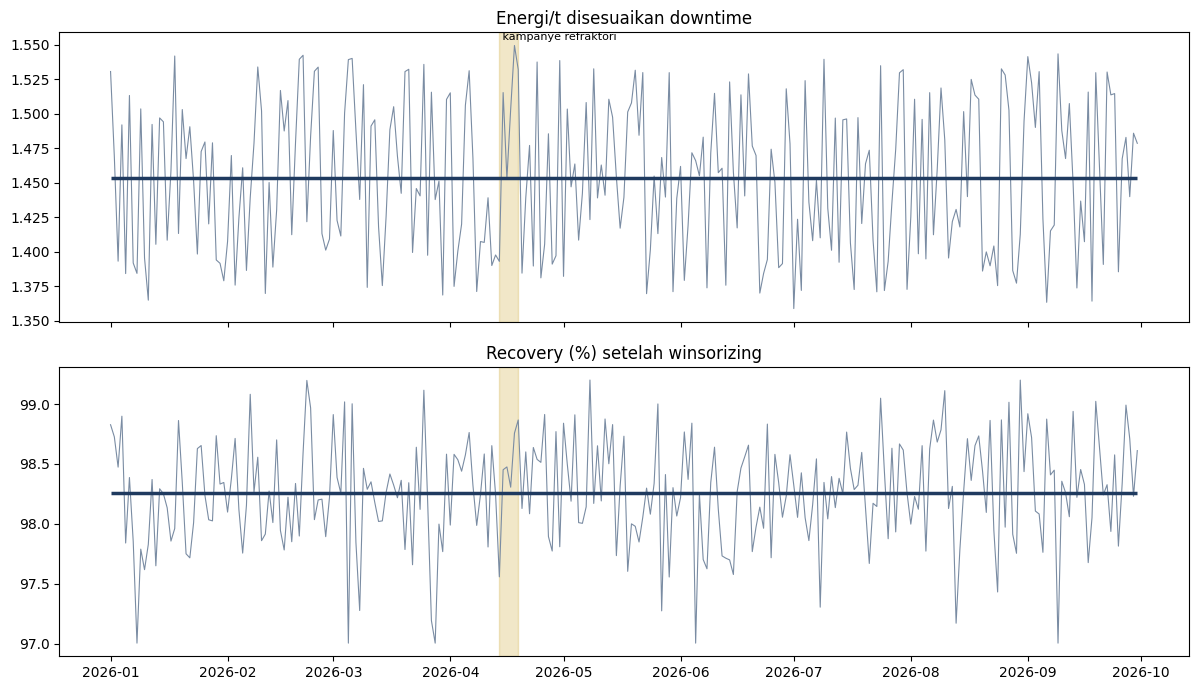

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for a, v, cps, ttl in [(ax[0], e_adj, cp_e_adj, "Energi/t disesuaikan downtime"), (ax[1], y_w, cp_y_w, "Recovery (%) setelah winsorizing")]:
    a.plot(T, v, color="#7A8CA3", lw=.8)
    b = [0] + list(cps) + [len(v)]
    for i in range(len(b) - 1): a.hlines(np.mean(v[b[i]:b[i+1]]), T[b[i]], T[b[i+1]-1], color="#1F3A5F", lw=2.5)
    for c_ in cps: a.axvline(T[c_], color="red", ls="--")
    a.axvspan(pd.Timestamp("2026-04-14"), pd.Timestamp("2026-04-19"), color="#C9A227", alpha=.25); a.set_title(ttl)
ax[0].text(pd.Timestamp("2026-04-14"), ax[0].get_ylim()[1], " kampanye refraktori", va="top", fontsize=8)
plt.tight_layout(); plt.show()

**Kesimpulan modul 7.**
*   Metode lolos uji pada data sintetis: titik asli 100 dan 180, terdeteksi 100 dan 183.
*   Energi per ton punya 0 titik perubahan. Lima titik pada recovery seluruhnya artefak pencilan dan hilang setelah winsorizing. Uji permutasi mendukung (p = 0,92 dan 0,44), jadi tidak ada pergeseran proses.

